### Import Libraries : Exhaustive list, not all being used

In [ ]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco

# statsmodels is a Python package that provides a complement to scipy for statistical computations
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

# Pyfolio package used for strategy backtesting
import pyfolio as pf

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

Module "zipline.assets" not found; mutltipliers will not be applied to position notionals.


In [2]:
stock = yf.download(tickers = 'MSFT', start='2020-01-01', end = '2022-12-31', progress = False)
benchmark = yf.download(tickers = '^GSPC', start='2020-01-01', end = '2022-12-31', progress = False)

stock['Return'] = stock['Close'].pct_change(periods = 1)
df_stock = stock.loc[:,['Close','Return']]
df_stock.dropna(inplace = True)

benchmark['Return'] = benchmark['Close'].pct_change(periods = 1)
df_benchmark = benchmark.loc[:,['Close','Return']]
df_benchmark.dropna(inplace = True)

### Drawdown

In financial trading, a drawdown refers to how much an account has fallen from its peak to its trough in terms of the capital or investment amount.

Your account is likely to witness whipsaws as share prices of the underlying stocks fluctuate in the market. Let’s say that the volatility sees your account dip to 90,000, but a previous uptrend pushed your account to peak at 120,000. Now, the drawdown is calculated from the peak that your account reached (120,000) and not from your initial capital (100,000). So, in this case, the drawdown experienced is 30,000 (120,000 – 90,000). Drawdown is measured over a specified period, between two distinct dates. Drawdown can be expressed in dollar amounts (as above) or as a percentage.

Thus, the formula for calculating drawdown as a percentage is as follows:
Drawdown (DD) % = ((Pmax – Pmin) / Pmax)) * 100

where
Pmin = Historical low (trough)
Pmax = Historical high (peak)


In [ ]:
def calc_drawdown(returns):
    '''
    Determines the drawdown  
    Parameters
    ----------
    returns : pd.Series
        Daily returns of an asset, noncumulative
    
    Returns
    -------
    drawdown : pd.Series    
    '''
    cum_return = np.cumprod(1 + returns)
    running_max = np.maximum.accumulate(cum_return)
    
    return (cum_return - running_max) / running_max
    

In [ ]:
drawdown = calc_drawdown(df_stock['Return'])
drawdown.plot(kind="area", color="salmon", alpha=0.5)
plt.title('Drawdown plot')
plt.show()

### Maximum Drawdown

The max drawdown differs from the drawdown by tracking the maximum drawdown of a 30-day rolling window of returns

In [ ]:
def calc_max_drawdown(returns):
    ''' 
    Determines the maximum drawdown
    
    Parameters
    ----------
    returns : pd.Series
        Daily returns of an asset, noncumulative
    
    Returns
    -------
    max_drawdown : float
    
    '''
    return np.min(calc_drawdown(returns))

In [ ]:
max_drawdown = df_stock['Return'].rolling(30).apply(calc_max_drawdown)
max_drawdown.plot(kind="area", color="salmon", alpha=0.5)
plt.title('Drawdown plot')
plt.show()

### Rolling Sharpe

While the traditional Sharpe ratio gives a single snapshot, the rolling Sharpe ratio provides a moving picture, recalculating the ratio over a fixed period as new data comes in. This rolling calculation offers a more immediate and ongoing analysis of the risk-adjusted performance, allowing investors to spot trends, volatility, and the impact of market events on investment returns.

The standard Sharpe ratio for strategy returns is given by the following formula:

$$S = \frac{\mathbb{E}(R_s - R_b)}{\sqrt{Var(R_s - R_b)}}$$
Where $R_{s}$ refers to the strategy return and  $R_{b}$ refers to benchmark return

In order to calculate an k-days rolling Sharpe ratio it is necessary to make two modifications to this formula. The first is to reduce the set of returns to the last trailing number of k-days trading periods (e.g. for daily data this means take the last k-days close-to-close returns). The second is to multiply the value by the square root of the number of k-days periods. 

$$S_t = \sqrt{k}\frac{\mathbb{E}(R_{s,t-k} - R_{b,t-k})}{\sqrt{Var(R_{s,t-k} - R_{b,t-k})}}$$

Where $R_{s,t-k}$ refers to the previous truncated strategy returns 

In [ ]:
# rolling window of 1 month (22 day), so it drops records wit
# risk free rate = 0 %


def rolling_sharpe(returns):
    return np.sqrt(22) * (returns.mean() / returns.std())

rolling_shapre = df_stock['Return'].rolling(window = 22).apply(rolling_sharpe)   

plt.plot(rolling_shapre, label = 'Rolling Sharpe')
plt.legend(loc='best')
plt.axhline(y= 0 , color = 'red',linestyle = '--')
plt.title('Rolling Sharpe ratio (1-month)')
plt.show()

### Rolling Beta

Interpretation of Market Beta
The weighted average of all market-betas with respect to the market index is 1.

- Beta>1: If a stock has a beta above 1, then it means that its return, on average, moves more than 1 to 1 with the return of the index
- Beta<1: If a stock has a beta below 1, then it means that its return, on average, moves less than 1 to 1 with the return of the index
- Beta<0: This case is uncommon, and it means that the stock tends to have an opposite direction to the market

In [3]:
df_benchmark

,Close,Return
Date,,
2020-01-03,3234.8501,-0.0071
2020-01-06,3246.2800,0.0035
2020-01-07,3237.1799,-0.0028
2020-01-08,3253.0500,0.0049
2020-01-09,3274.7000,0.0067
...,...,...
2022-12-23,3844.8201,0.0059
2022-12-27,3829.2500,-0.0040
2022-12-28,3783.2200,-0.0120


In [4]:
df_stock

,Close,Return
Date,,
2020-01-03,158.6200,-0.0125
2020-01-06,159.0300,0.0026
2020-01-07,157.5800,-0.0091
2020-01-08,160.0900,0.0159
2020-01-09,162.0900,0.0125
...,...,...
2022-12-23,238.7300,0.0023
2022-12-27,236.9600,-0.0074
2022-12-28,234.5300,-0.0103


In [5]:
# make sure both the variables have same length so use inner join using datetime index as key 

df = df_stock.merge(df_benchmark,how= 'inner',left_index = True, right_index=True,suffixes=('_Stock','_Benchmark'))

In [6]:
df

,Close_Stock,Return_Stock,Close_Benchmark,Return_Benchmark
Date,,,,
2020-01-03,158.6200,-0.0125,3234.8501,-0.0071
2020-01-06,159.0300,0.0026,3246.2800,0.0035
2020-01-07,157.5800,-0.0091,3237.1799,-0.0028
2020-01-08,160.0900,0.0159,3253.0500,0.0049
2020-01-09,162.0900,0.0125,3274.7000,0.0067
...,...,...,...,...
2022-12-23,238.7300,0.0023,3844.8201,0.0059
2022-12-27,236.9600,-0.0074,3829.2500,-0.0040
2022-12-28,234.5300,-0.0103,3783.2200,-0.0120


In [ ]:
# rolling window of 1 month (22 day)

def rolling_beta(df,window):
    ''' 
    df = dataframe with both independent and depedendent variables
    window = The length of the rolling window
     
    It returns betas of the rolling regression
    '''
    
    n_obs = df.shape[0]
    beta = np.full(n_obs, np.NaN)
    
    for t in range(window-1, n_obs):
        model = LinearRegression()   
        model.fit(X = df.iloc[t-window+1:t+1,1].to_frame() , y= df.iloc[t-window+1:t+1,3])           
        beta[t]  = model.coef_[0]                                        
    
    return beta


In [ ]:
rolling_beta = rolling_beta(df,22)
plt.plot(rolling_beta)
plt.title("Rolling Beta: Stock vs Benachmark with 1 month rolling window")
plt.show()

# Pyfolio Package

In [2]:
data = yf.download(tickers = ['IBM','IBN','^GSPC'], start = '2015-01-01', end = '2022-12-31', progress= False)
data = data['Close']

In [3]:
data['Return_IBM'] = data['IBM'].pct_change()
data['Return_IBN'] = data['IBN'].pct_change()
data['Return_Benchmark'] = data['^GSPC'].pct_change()
data.dropna(inplace = True)
returns = data[['Return_IBM','Return_IBN','Return_Benchmark']]

In [4]:
strategy_returns = returns[['Return_IBM','Return_IBN']].apply(lambda x:x.mean(),axis =1)

Start date,2015-01-05
End date,2022-12-30
Total months,95
,Backtest
Annual return,5.5%
Cumulative returns,53.3%
Annual volatility,25.1%
Sharpe ratio,0.34
Calmar ratio,0.12
Stability,0.67
Max drawdown,-47.2%


Worst drawdown periods,Net drawdown in %,Peak date,Valley date,Recovery date,Duration
0,47.24,2020-02-12,2020-03-23,2021-04-26,314
1,42.28,2015-01-26,2016-02-11,2018-01-16,777
2,23.61,2018-01-26,2018-10-30,2019-07-18,385
3,16.91,2022-02-02,2022-03-07,2022-08-12,138
4,12.95,2019-07-29,2019-08-22,2019-11-25,86


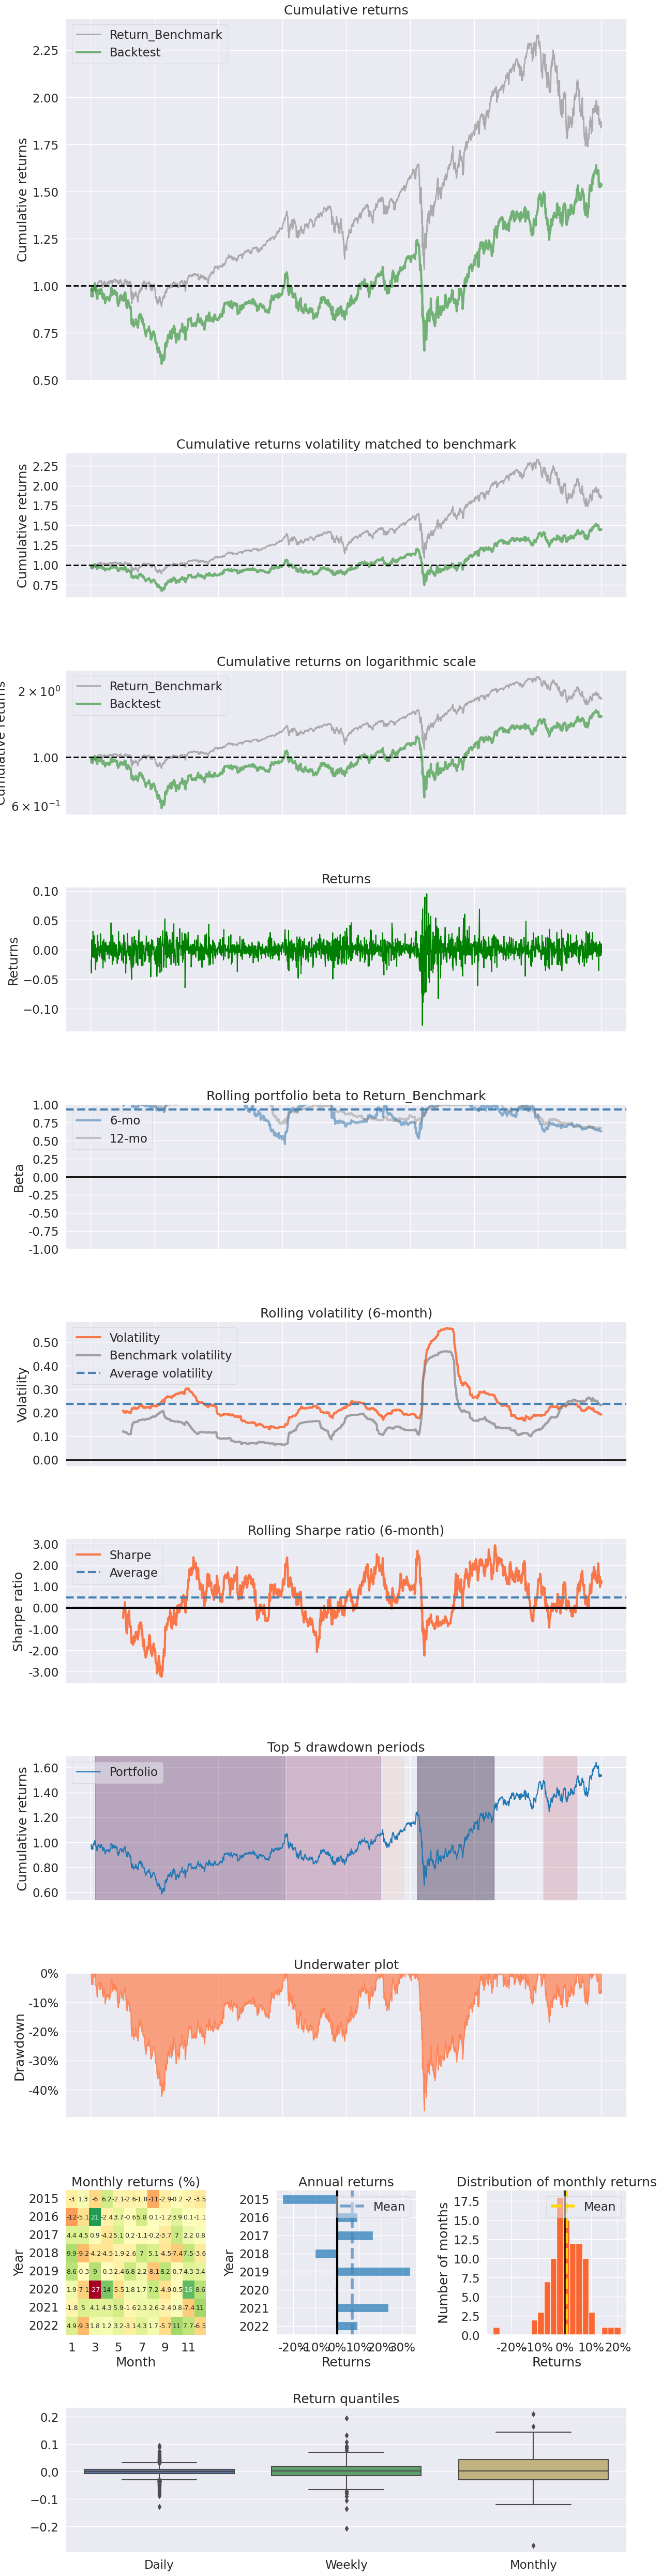

In [6]:
pf.create_returns_tear_sheet(strategy_returns, benchmark_rets=returns['Return_Benchmark'])

- it is always better to use rolling estimatses than single etimates in Quant Finance
- beta of the strategy is 0.91 means that it has lower volatility than the market.
- try to backtest tradng strategy on out-of-sample data due to overfitting problem on in-sample data